## Task 1: Multi-Class Benchmark Classification Pipeline (Iris Dataset)

---

### 📌 Project Overview & Requirements
Implement an end-to-end supervised classification pipeline using Python and Scikit-Learn on the Iris dataset.
- Load the benchmark Iris dataset via Pandas directly from the source URL
- Perform exploratory data analysis with a Seaborn pairplot
- Normalize features using `StandardScaler`
- Split the dataset into 80% training and 20% testing sets
- Train **Logistic Regression** and **Decision Tree Classifier** models
- Benchmark classification performance (Accuracy, Precision, Recall, F1-Score)
- Plot confusion matrix heatmaps and 2D decision boundaries

## Step 1: Downloading required libraries


In [10]:
!pip install scikit-learn pandas matplotlib seaborn


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Step 2: Importing all libraries


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Set plot aesthetic style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100

## Step 3: Load Iris Dataset from Source URL
Load the Iris CSV dataset directly into a Pandas DataFrame using the provided GitHub URL.

In [3]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)

print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Step 4: Exploratory Data Analysis (Pairplot)
Visualize feature distributions and pairwise relationships across the three Iris species (`setosa`, `versicolor`, `virginica`).

<Figure size 1000x800 with 0 Axes>

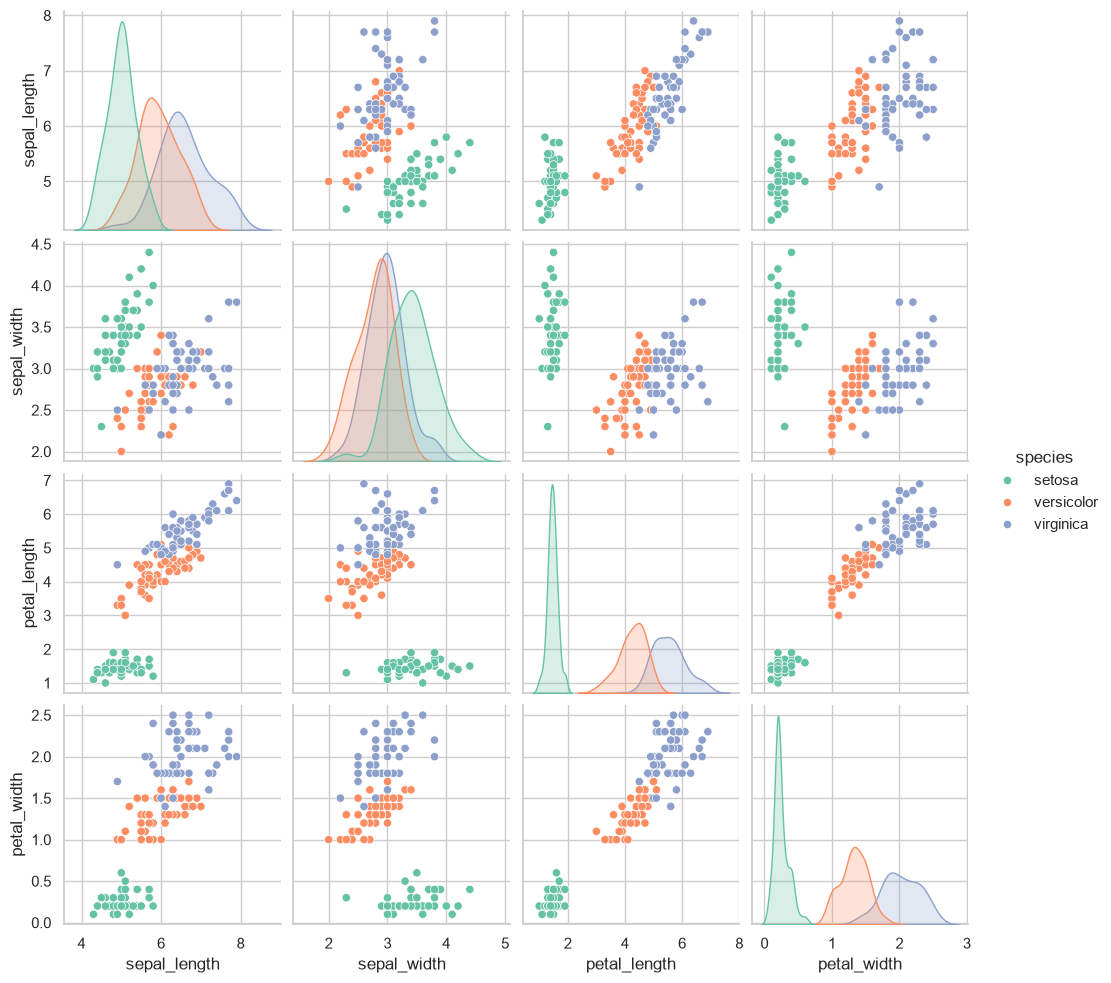

In [4]:
plt.figure(figsize=(10, 8))
sns.pairplot(df, hue="species", palette="Set2")
plt.savefig("exploratory_pairplot.png")
plt.show()

## Step 5: Train-Test Split & Feature Scaling
Separate features and target labels, split into an 80/20 stratified train/test set, and normalize continuous features using `StandardScaler`.

In [5]:
X = df.drop(columns=["species"])
y = df["species"]

# Encode string target labels into numeric integers if needed, or let sklearn handle it
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training feature set shape: {X_train_scaled.shape}")
print(f"Testing feature set shape: {X_test_scaled.shape}")

Training feature set shape: (120, 4)
Testing feature set shape: (30, 4)


## Step 6: Model Training & Benchmark Evaluation
Train Logistic Regression and Decision Tree Classifiers, then evaluate performance using Accuracy, Precision, Recall, and F1-Score.

In [6]:
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Decision Tree Classifier": DecisionTreeClassifier(random_state=42)
}

results = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    
    acc = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, target_names=encoder.classes_, output_dict=True)
    
    results[name] = {
        "y_pred": y_pred,
        "accuracy": acc,
        "report": report
    }
    
    print(f"=== {name} Performance ===")
    print(f"  • Accuracy:  {acc * 100:.2f}%")
    print(f"  • Macro F1:  {report['macro avg']['f1-score']:.4f}\n" + "-" * 40)

=== Logistic Regression Performance ===
  • Accuracy:  93.33%
  • Macro F1:  0.9333
----------------------------------------
=== Decision Tree Classifier Performance ===
  • Accuracy:  93.33%
  • Macro F1:  0.9333
----------------------------------------


## Step 7: Confusion Matrix Heatmap Visualization
Plot side-by-side confusion matrix heatmaps to inspect classification errors per species.

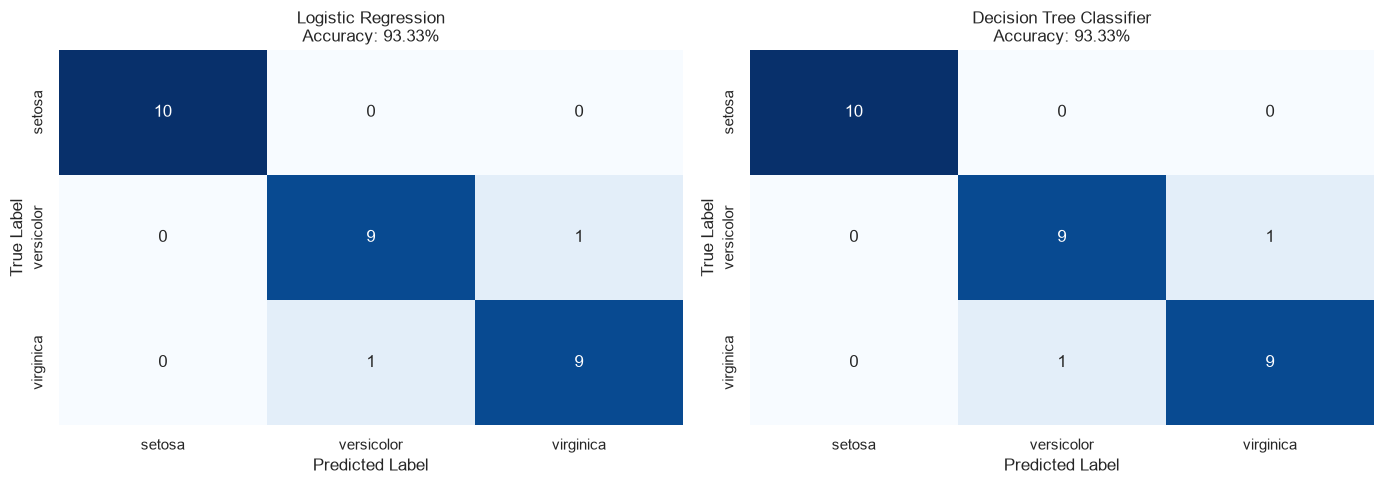

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, (name, res) in enumerate(results.items()):
    ax = axes[idx]
    cm = confusion_matrix(y_test, res["y_pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=encoder.classes_, yticklabels=encoder.classes_)
    ax.set_title(f"{name}\nAccuracy: {res['accuracy']*100:.2f}%")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()
plt.savefig("confusion_matrices.png")
plt.show()

## Step 8: 2D Decision Boundary Visualization
Visualize how Logistic Regression and Decision Trees partition feature space using two primary features (`petal_length` and `petal_width`).

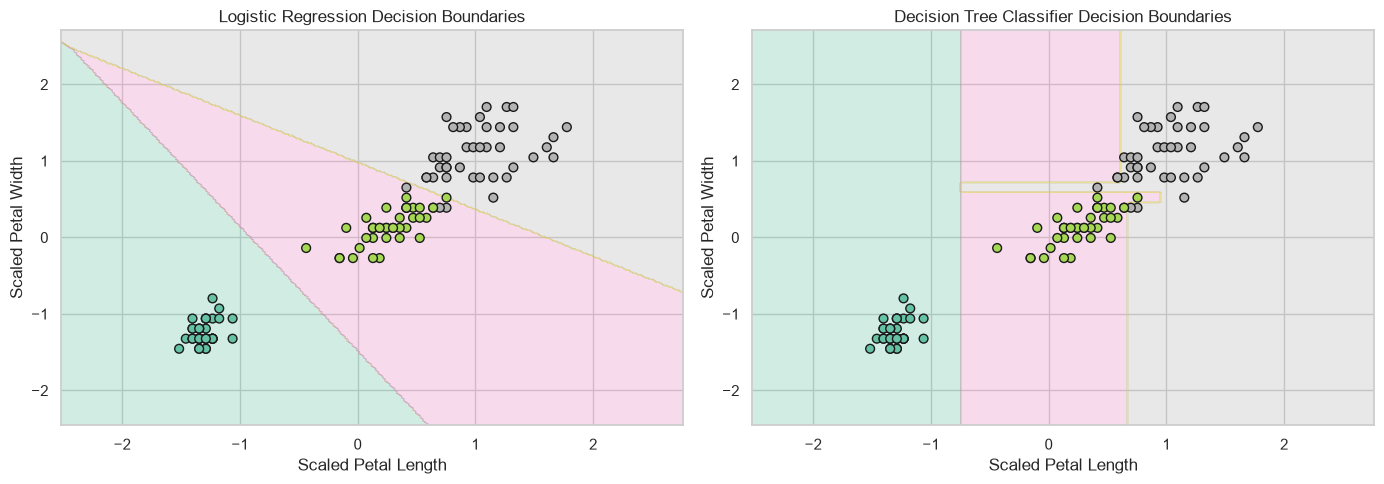

In [8]:
# Select two features for 2D boundary plotting: petal_length (index 2) and petal_width (index 3)
X_2d = X_train_scaled[:, [2, 3]]
y_2d = y_train

# Fit models on 2D data for visualization purposes
clf_lr = LogisticRegression(random_state=42).fit(X_2d, y_2d)
clf_dt = DecisionTreeClassifier(random_state=42).fit(X_2d, y_2d)

x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, (name, clf) in enumerate([("Logistic Regression", clf_lr), ("Decision Tree Classifier", clf_dt)]):
    ax = axes[idx]
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Set2)
    scatter = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y_2d, edgecolor='k', cmap=plt.cm.Set2, s=40)
    ax.set_title(f"{name} Decision Boundaries")
    ax.set_xlabel("Scaled Petal Length")
    ax.set_ylabel("Scaled Petal Width")

plt.tight_layout()
plt.savefig("decision_boundaries.png")
plt.show()

## Step 9: Conclusion & Key Findings
Summarize the comparative performance between Logistic Regression and Decision Tree Classifier on the Iris dataset.

In [9]:
print("=" * 50)
print("📌 TASK 1: CLASSIFICATION PIPELINE CONCLUSION")
print("=" * 50)
for name, res in results.items():
    print(f"• {name}:")
    print(f"    - Accuracy: {res['accuracy'] * 100:.2f}%")
    print(f"    - Macro Precision: {res['report']['macro avg']['precision']:.4f}")
    print(f"    - Macro Recall:    {res['report']['macro avg']['recall']:.4f}")
    print(f"    - Macro F1-Score:  {res['report']['macro avg']['f1-score']:.4f}")
print("=" * 50)
print("Conclusion: Both models performed exceptionally well on the Iris dataset, "
      "with linear decision boundaries of Logistic Regression and axis-aligned "
      "splits of the Decision Tree achieving high benchmark accuracy.")
print("=" * 50)

📌 TASK 1: CLASSIFICATION PIPELINE CONCLUSION
• Logistic Regression:
    - Accuracy: 93.33%
    - Macro Precision: 0.9333
    - Macro Recall:    0.9333
    - Macro F1-Score:  0.9333
• Decision Tree Classifier:
    - Accuracy: 93.33%
    - Macro Precision: 0.9333
    - Macro Recall:    0.9333
    - Macro F1-Score:  0.9333
Conclusion: Both models performed exceptionally well on the Iris dataset, with linear decision boundaries of Logistic Regression and axis-aligned splits of the Decision Tree achieving high benchmark accuracy.
